# P2 · Frozen MERT features + team-trained valence/arousal head

**ECE 539 Integration Project — Mood Music Recommender (Team G16)** · owner: **P2** (`hsniko0522`)

Where this sits in the pipeline:

`DEAM audio` → **C1 MERT-v1-95M (frozen, pretrained)** → 13 × 768 time-averaged embedding → **C2 MLP head (trained by us)** → predicted *(valence, arousal)* on DEAM's 1–9 scale → **C4 ranker (P4)**

**Nov 15 checkpoint:** cached MERT features · trained MLP · initial dev R² / RMSE.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Run all.
MERT features are cached per song on Drive, so a disconnect only loses the song in progress and a rerun skips everything already done.

| Input | Where |
|---|---|
| `DEAM_audio.zip` (needed), `DEAM_Annotations.zip`, `metadata.zip` | `MyDrive/ECE539-mood-music/data/` |
| P1's split `song_split_ids.csv` and openSMILE table `deam_combined_500.csv` | Abbey's shared `ECE539_P1` folder → add a shortcut to *My Drive* so it is at `MyDrive/ECE539_P1/` |

With P1's folder in place, P2 uses **exactly P1's 500 songs and train/dev/test split**, so MERT results are directly comparable with P1's Ridge baseline, and the head is also trained on P1's openSMILE features (the proposal's controlled comparison).
The annotation CSVs are also read from `ECE539_P1/data/`, so `DEAM_audio.zip` is the only zip you must add yourself.

| Output (`MyDrive/ECE539-mood-music/outputs/p2/`) | For |
|---|---|
| `p2_va_for_p4.csv` — `song_id, split, valence, arousal` (same columns P4 already reads) | P4 ranker |
| `va_predictions.csv` — `song_id, split, valence/arousal true + pred` | evaluation |
| `va_head.pt`, `va_head_config.json` | final notebook / demo |
| `mert_embeddings.npz` (all 13 layers) | anyone who needs MERT features |
| `layer_sweep_dev.*`, `dev_summary.csv`, `training_curves_and_dev_scatter.png` | Progress report, P2 appendix |

**Fair-test rule (from the proposal):** the layer, hyper-parameters and standardization are chosen on **train/dev only**. The test metrics cell is switched off until the team freezes every choice.

> Tip: if the team folder was shared with you, open it in Drive → "Organize → Add shortcut" → *My Drive*, so it appears under `MyDrive/`.

## 0 · Setup

In [19]:
# MERT's custom code (trust_remote_code) breaks on transformers >= 4.44, so pin the last compatible release.
# If Colab asks you to restart the session after this, restart and continue from the next cell.
# If this install itself fails (e.g. a newer Colab Python), skip it: the MERT cell below also patches newer versions.
!pip -q install "transformers==4.43.4"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> tokenizers


In [20]:
import os, sys, glob, json, time, zipfile, random, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import librosa
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# ---- Paths: change PROJECT_DIR if the team folder lives somewhere else ----
PROJECT_DIR  = os.environ.get('P2_PROJECT_DIR', '/content/drive/MyDrive/ECE539-mood-music')
DATA_ZIP_DIR = os.path.join(PROJECT_DIR, 'data')                  # DEAM zip files (shared with P1)
LOCAL_DATA   = os.environ.get('P2_LOCAL_DATA', '/content/deam')   # unzipped copy on fast local disk
CACHE_DIR    = os.path.join(PROJECT_DIR, 'cache', 'mert_v1_95m')  # one .npy per song, survives disconnects
OUT_DIR      = os.path.join(PROJECT_DIR, 'outputs', 'p2')
P1_DIR       = os.environ.get('P2_P1_DIR', '/content/drive/MyDrive/Colab Notebooks/ECE539_P1')   # Abbey's shared P1 folder
P1_FEATURES  = os.path.join(P1_DIR, 'data', 'deam_combined_500.csv')             # P1's openSMILE table
_split_candidates = sorted(glob.glob(os.path.join(P1_DIR, 'splits', 'song_split_ids*.csv'))) + \
                    [os.path.join(PROJECT_DIR, 'splits.csv')]
SPLITS_CSV   = next((p for p in _split_candidates if os.path.exists(p)), None)   # P1's official split
print('P1 folder found:', os.path.isdir(P1_DIR), '| split file:', SPLITS_CSV)
for d in (DATA_ZIP_DIR, CACHE_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)

# ---- Settings ----
SEED = 42
MERT_ID = 'm-a-p/MERT-v1-95M'
CHUNK_S = 5.0          # MERT-v1 was pre-trained on 5 s contexts
MIN_TAIL_S = 1.0       # drop a last chunk shorter than this
BATCH_CHUNKS = 16      # chunks per forward pass (use 8 if the GPU runs out of memory)
SUBSET_N = None        # e.g. 500 for a quick first run; None = every song that has audio + labels
TARGETS = ['valence_mean', 'arousal_mean']   # DEAM song-level static ratings, 1-9 scale

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()
print('device:', DEVICE, '| torch', torch.__version__)
if DEVICE == 'cpu':
    print('WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then rerun.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
P1 folder found: True | split file: /content/drive/MyDrive/Colab Notebooks/ECE539_P1/splits/song_split_ids.csv
device: cuda | torch 2.14.1+cu130


## 1 · Data: DEAM audio, song-level labels, artist-grouped splits

DEAM gives each song one averaged **valence** (negative ↔ positive) and **arousal** (calm ↔ energetic) rating on a 1–9 scale.
The zips stay on Drive; each session unzips them to the Colab disk (much faster to read than Drive).

In [21]:
# 1a. (Optional) download DEAM straight into Drive.
# Needed: DEAM_audio.zip, DEAM_Annotations.zip, metadata.zip  (the features zip is only for P1's openSMILE baseline).
# On https://cvml.unige.ch/databases/DEAM/ right-click each download link -> "Copy link address" and paste below.
# Skip this cell if the zips are already in DATA_ZIP_DIR (e.g. P1 already put them in the shared folder).
DEAM_URLS = [
    # 'https://...',
]
for url in DEAM_URLS:
    !wget -q -c -P "{DATA_ZIP_DIR}" "{url}"
print(sorted(os.listdir(DATA_ZIP_DIR)))

['DEAM_Annotations.zip', 'DEAM_audio.zip', 'metadata.zip']


In [22]:
# 1b. Unzip to local disk and find audio, labels and artists.
def unzip_all(src_dir, dst_dir, skip=('feature',)):
    # Extract every DEAM zip (and any zip nested inside one) once per session.
    os.makedirs(dst_dir, exist_ok=True)
    todo = sorted(glob.glob(os.path.join(src_dir, '*.zip')))
    if not todo:
        raise FileNotFoundError(f'No .zip files in {src_dir}. Put the DEAM zips there first (cell 1a).')
    done = set()
    while todo:
        z = todo.pop(0)
        if z in done or any(s in os.path.basename(z).lower() for s in skip):
            done.add(z)
            continue
        marker = os.path.join(dst_dir, '.unzipped_' + os.path.basename(z))
        if not os.path.exists(marker):
            print('unzipping', os.path.basename(z), '...')
            with zipfile.ZipFile(z) as zf:
                zf.extractall(dst_dir)
            open(marker, 'w').close()
        done.add(z)
        todo += [p for p in glob.glob(os.path.join(dst_dir, '**', '*.zip'), recursive=True) if p not in done]

def load_static_labels(roots):
    files = sorted({f for root in roots if os.path.isdir(root)
                    for f in glob.glob(os.path.join(root, '**', '*static_annotations_averaged_songs*.csv'), recursive=True)})
    if not files:
        raise FileNotFoundError('No static_annotations_averaged_songs_*.csv found. Add DEAM_Annotations.zip to the data '
                                'folder or add the ECE539_P1 shortcut to My Drive.')
    parts = []
    for f in files:
        df = pd.read_csv(f, skipinitialspace=True)
        df.columns = [c.strip().lower() for c in df.columns]
        missing = {'song_id', *TARGETS} - set(df.columns)
        if missing:
            raise KeyError(f'{os.path.basename(f)} lacks {missing}; columns are {list(df.columns)}')
        parts.append(df[['song_id', *TARGETS]])
    out = pd.concat(parts).dropna()
    out['song_id'] = out['song_id'].astype(int)
    return out.drop_duplicates('song_id').reset_index(drop=True)

def load_artists(root):
    # Artist per song from DEAM's metadata CSVs (column names differ by year, so match loosely).
    files = set(glob.glob(os.path.join(root, '**', 'metadata*', '*.csv'), recursive=True))
    files |= set(glob.glob(os.path.join(root, '**', 'metadata_*.csv'), recursive=True))
    parts = []
    for f in sorted(files):
        try:
            df = pd.read_csv(f, sep=None, engine='python', encoding='latin-1')
        except Exception as e:
            print('skipping', os.path.basename(f), e)
            continue
        cols = {c.strip().lower(): c for c in df.columns}
        id_col = next((cols[k] for k in ('song_id', 'id', 'song id') if k in cols), None)
        art_col = next((cols[k] for k in cols if 'artist' in k), None)
        if id_col and art_col:
            parts.append(pd.DataFrame({'song_id': pd.to_numeric(df[id_col], errors='coerce'),
                                       'artist': df[art_col].astype(str).str.strip().str.lower()}))
    if not parts:
        print('WARNING: no artist metadata found; each song becomes its own group.')
        return pd.DataFrame({'song_id': pd.Series(dtype=int), 'artist': pd.Series(dtype=str)})
    a = pd.concat(parts).dropna(subset=['song_id'])
    a['song_id'] = a['song_id'].astype(int)
    return a.drop_duplicates('song_id')

unzip_all(DATA_ZIP_DIR, LOCAL_DATA)
audio_paths = {int(Path(p).stem): p
               for p in glob.glob(os.path.join(LOCAL_DATA, '**', '*.mp3'), recursive=True)
               if Path(p).stem.isdigit()}
labels = load_static_labels([LOCAL_DATA, os.path.join(P1_DIR, 'data')])
artists = load_artists(LOCAL_DATA)

songs = labels[labels.song_id.isin(audio_paths.keys())].merge(artists, on='song_id', how='left')
songs['artist'] = songs['artist'].replace({'': np.nan, 'nan': np.nan})
songs['artist'] = songs['artist'].fillna('unknown_' + songs['song_id'].astype(str))
songs['path'] = songs['song_id'].map(audio_paths)
print(f'audio files: {len(audio_paths)} | labelled songs: {len(labels)} | usable: {len(songs)} | artists: {songs.artist.nunique()}')
print(songs[TARGETS].describe().round(2).to_string())

skipping metadata_2015.csv Expected 7 fields in line 31, saw 20
audio files: 1802 | labelled songs: 1802 | usable: 1802 | artists: 1469
       valence_mean  arousal_mean
count       1802.00       1802.00
mean           4.90          4.81
std            1.17          1.28
min            1.60          1.60
25%            4.10          3.80
50%            4.90          4.90
75%            5.80          5.80
max            8.40          8.10


In [23]:
# 1c. Splits. Use P1's official split file when it exists (same 500 songs and partitions as P1's
#     baseline); otherwise make a provisional 70/15/15 split where each artist lands in one split.
def make_group_split(df, seed=SEED):
    g = df['artist'].to_numpy()
    tr, rest = next(GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed).split(df, groups=g))
    dv, te = next(GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed).split(rest, groups=g[rest]))
    split = np.empty(len(df), dtype=object)
    split[tr], split[rest[dv]], split[rest[te]] = 'train', 'dev', 'test'
    return split

if SPLITS_CSV:
    official = pd.read_csv(SPLITS_CSV)
    official.columns = [c.strip().lower() for c in official.columns]
    split_col = next((c for c in ('split', 'set', 'subset', 'partition') if c in official.columns), None)
    if 'song_id' not in official.columns or split_col is None:
        raise KeyError(f'{SPLITS_CSV} needs a song_id column and a split column; found {list(official.columns)}')
    official['split'] = (official[split_col].astype(str).str.strip().str.lower()
                         .replace({'val': 'dev', 'valid': 'dev', 'validation': 'dev', 'development': 'dev'}))
    n_official = len(official)
    songs = songs.merge(official[['song_id', 'split']], on='song_id', how='inner')
    SPLIT_SOURCE = f'P1 split ({os.path.basename(SPLITS_CSV)})'
    print(f'P1 split lists {n_official} songs; {len(songs)} of them have audio here.')
else:
    if SUBSET_N:
        songs = songs.sample(n=min(SUBSET_N, len(songs)), random_state=SEED)
    songs = songs.reset_index(drop=True)
    songs['split'] = make_group_split(songs)
    songs[['song_id', 'artist', 'split']].to_csv(os.path.join(OUT_DIR, 'provisional_splits.csv'), index=False)
    SPLIT_SOURCE = 'provisional P2 split (replace with P1 splits.csv when ready)'

songs = songs.sort_values('song_id').reset_index(drop=True)
leaky = int((songs.groupby('artist')['split'].nunique() > 1).sum())
print('split source:', SPLIT_SOURCE, '| artists appearing in >1 split:', leaky)
print(songs.groupby('split')[TARGETS].agg(['count', 'mean', 'std']).round(2).to_string())

P1 split lists 500 songs; 500 of them have audio here.
split source: P1 split (song_split_ids.csv) | artists appearing in >1 split: 25
      valence_mean             arousal_mean            
             count  mean   std        count  mean   std
split                                                  
dev             75  4.75  1.09           75  4.92  1.24
test            75  4.90  1.24           75  4.88  1.33
train          350  4.95  1.15          350  4.87  1.27


## 2 · C1: frozen MERT-v1-95M embeddings

Each song is resampled to 24 kHz mono and cut into 5 s chunks (MERT's pre-training context).
MERT returns 13 hidden states (CNN front end + 12 Transformer layers), each 768-d at about 75 frames/s.
We average every layer over all frames of the song → one **13 × 768** array per song, saved to Drive.
All 13 layers are kept because which layer carries emotion best is chosen later on the dev split.
MERT is never updated (`requires_grad=False`, `torch.no_grad()`).

In [24]:
from transformers import AutoConfig, AutoModel, Wav2Vec2FeatureExtractor

config = AutoConfig.from_pretrained(MERT_ID, trust_remote_code=True)
if not hasattr(config, 'conv_pos_batch_norm'):    # only matters if a newer transformers sneaks in
    config.conv_pos_batch_norm = False
mert = AutoModel.from_pretrained(MERT_ID, config=config, trust_remote_code=True).to(DEVICE).eval()
processor = Wav2Vec2FeatureExtractor.from_pretrained(MERT_ID, trust_remote_code=True)
for p in mert.parameters():
    p.requires_grad_(False)                        # C1 stays frozen
SR = processor.sampling_rate                       # 24 kHz
amp = (lambda: torch.autocast('cuda', dtype=torch.float16)) if DEVICE == 'cuda' else contextlib.nullcontext

def mert_hidden_states(x):
    # Returns 13 tensors (batch, frames, 768): the encoder input + the output of each of the 12 Transformer layers.
    # Old transformers fill outputs.hidden_states; new ones (v5+) ignore the flag inside MERT's custom code and
    # return None, so there we record exactly the same tensors with forward hooks on the encoder layers.
    if not USE_HOOKS:
        return tuple(mert(x, output_hidden_states=True).hidden_states)
    layers, captured = mert.encoder.layers, []
    def grab_input(module, args, kwargs):
        captured.append(args[0] if args else kwargs['hidden_states'])
    def grab_output(module, args, output):
        captured.append(output[0] if isinstance(output, (tuple, list)) else output)
    handles = [layers[0].register_forward_pre_hook(grab_input, with_kwargs=True)]
    handles += [layer.register_forward_hook(grab_output) for layer in layers]
    try:
        mert(x)
    finally:
        for h in handles:
            h.remove()
    return tuple(captured)

# Sanity check on 5 s of noise: expect 13 hidden states x 768-d and ~375 frames.
with torch.no_grad(), amp():
    USE_HOOKS = mert(torch.randn(1, int(CHUNK_S * SR), device=DEVICE), output_hidden_states=True).hidden_states is None
    hs = mert_hidden_states(torch.randn(1, int(CHUNK_S * SR), device=DEVICE))
N_LAYERS, D = len(hs), hs[-1].shape[-1]
assert N_LAYERS == 13 and D == 768, f'unexpected MERT output: {N_LAYERS} states x {D}-d'
import transformers
print('transformers', transformers.__version__, '| hidden states via', 'forward hooks' if USE_HOOKS else 'output_hidden_states')
print(f'MERT ok: {N_LAYERS} hidden states x {D}-d, {hs[-1].shape[1]} frames per {CHUNK_S:.0f} s chunk, '
      f'{sum(p.numel() for p in mert.parameters()) / 1e6:.1f}M frozen parameters')

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

transformers 5.22.1 | hidden states via forward hooks
MERT ok: 13 hidden states x 768-d, 374 frames per 5 s chunk, 94.4M frozen parameters


In [25]:
def embed_audio(path):
    # Audio file -> (13, 768) MERT embedding: mean over every frame of every 5 s chunk.
    wav, _ = librosa.load(path, sr=SR, mono=True)
    step = int(CHUNK_S * SR)
    chunks = [wav[i:i + step] for i in range(0, len(wav), step)]
    chunks = [c for c in chunks if len(c) >= MIN_TAIL_S * SR] or [wav]
    full = [c for c in chunks if len(c) == step]
    groups = [full[i:i + BATCH_CHUNKS] for i in range(0, len(full), BATCH_CHUNKS)]
    groups += [[c] for c in chunks if len(c) != step]           # a short last chunk runs on its own
    total, n_frames = np.zeros((N_LAYERS, D)), 0
    for group in groups:
        x = processor(group, sampling_rate=SR, return_tensors='pt')['input_values'].to(DEVICE)
        with torch.no_grad(), amp():
            hs = mert_hidden_states(x)
        h = torch.stack(hs, dim=1).float()                        # (batch, 13, frames, 768)
        total += h.sum(dim=(0, 2)).cpu().numpy()
        n_frames += h.shape[0] * h.shape[2]
    emb = total / n_frames
    if not np.isfinite(emb).all():
        raise ValueError('non-finite embedding')
    return emb.astype(np.float16)

cache_path = lambda sid: os.path.join(CACHE_DIR, f'{sid}.npy')
todo = [s for s in songs.song_id if not os.path.exists(cache_path(s))]
print(f'{len(songs) - len(todo)} songs already cached, {len(todo)} to extract')
failed, t0 = [], time.time()
for i, sid in enumerate(todo, 1):
    try:
        np.save(cache_path(sid), embed_audio(audio_paths[sid]))
    except Exception as e:
        failed.append((sid, repr(e)))
    if i % 50 == 0 or i == len(todo):
        rate = i / (time.time() - t0)
        print(f'{i}/{len(todo)}  {rate:.2f} songs/s  ETA {(len(todo) - i) / rate / 60:.1f} min')
if failed:
    print(f'{len(failed)} songs failed, e.g.', failed[:3])
    pd.DataFrame(failed, columns=['song_id', 'error']).to_csv(os.path.join(OUT_DIR, 'mert_failed.csv'), index=False)

500 songs already cached, 0 to extract


In [26]:
# Load the cache into one array and save a single-file copy for teammates.
songs = songs[songs.song_id.map(lambda s: os.path.exists(cache_path(s)))].reset_index(drop=True)
EMB = np.stack([np.load(cache_path(s)).astype(np.float32) for s in songs.song_id])   # (N, 13, 768)
Y = songs[TARGETS].to_numpy(np.float32)                                                # (N, 2)
SPLIT_IDX = {k: np.flatnonzero(songs['split'].to_numpy() == k) for k in ('train', 'dev', 'test')}
np.savez_compressed(os.path.join(OUT_DIR, 'mert_embeddings.npz'),
                    song_id=songs.song_id.to_numpy(), emb=EMB.astype(np.float16))
print('embeddings', EMB.shape, '| songs per split', {k: len(v) for k, v in SPLIT_IDX.items()})

embeddings (500, 13, 768) | songs per split {'train': 350, 'dev': 75, 'test': 75}


## 3 · C2: the valence/arousal head we train

`768 → 256 → 2` with ReLU and dropout (≈197k parameters, the only weights updated in the whole pipeline).
- **Inputs** are standardized with **train-split** mean/std; **targets** too, so valence and arousal weigh equally in the MSE loss.
- **Adam**, mini-batches of 64, **early stopping** on dev MSE (patience 30); the best-dev weights are restored.
- Predictions are mapped back to DEAM's 1–9 scale before computing **R²** and **RMSE**.

In [27]:
class VAHead(nn.Module):
    # C2: the team-trained component.
    def __init__(self, d_in=768, d_hidden=256, p_drop=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(d_hidden, 2))
    def forward(self, x):
        return self.net(x)

def layer_features(layer):
    # One MERT layer (0-12) or the average of all 13 ('avg'), as an (N, 768) matrix.
    return EMB.mean(axis=1) if layer == 'avg' else EMB[:, int(layer), :]

def va_metrics(y_true, y_pred):
    m = {}
    for j, name in enumerate(['valence', 'arousal']):
        m[f'{name}_r2'] = r2_score(y_true[:, j], y_pred[:, j])
        m[f'{name}_rmse'] = float(np.sqrt(np.mean((y_true[:, j] - y_pred[:, j]) ** 2)))
    m['mean_r2'] = (m['valence_r2'] + m['arousal_r2']) / 2
    return m

DEFAULT_HP = dict(d_hidden=256, p_drop=0.3, lr=1e-3, weight_decay=1e-4, batch_size=64, max_epochs=400, patience=30)

def train_head(X, Y, tr, dv, hp=DEFAULT_HP, seed=SEED):
    # Train C2 on rows `tr`, early-stop on rows `dv`. Works for any (N, d) features, e.g. openSMILE later.
    set_seed(seed)
    x_mu, x_sd = X[tr].mean(0), X[tr].std(0) + 1e-6
    y_mu, y_sd = Y[tr].mean(0), Y[tr].std(0)
    Xs = torch.tensor((X - x_mu) / x_sd, dtype=torch.float32, device=DEVICE)
    Ys = torch.tensor((Y - y_mu) / y_sd, dtype=torch.float32, device=DEVICE)
    tr_t, dv_t = torch.as_tensor(tr, device=DEVICE), torch.as_tensor(dv, device=DEVICE)
    model = VAHead(X.shape[1], hp['d_hidden'], hp['p_drop']).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=hp['lr'], weight_decay=hp['weight_decay'])
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(seed)
    hist, best, wait, best_epoch, best_state = {'train': [], 'dev': []}, float('inf'), 0, 0, None
    for epoch in range(hp['max_epochs']):
        model.train()
        order = tr_t[torch.randperm(len(tr), generator=gen).to(DEVICE)]
        for i in range(0, len(order), hp['batch_size']):
            b = order[i:i + hp['batch_size']]
            opt.zero_grad()
            loss_fn(model(Xs[b]), Ys[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            hist['train'].append(loss_fn(model(Xs[tr_t]), Ys[tr_t]).item())
            hist['dev'].append(loss_fn(model(Xs[dv_t]), Ys[dv_t]).item())
        if hist['dev'][-1] < best - 1e-5:
            best, wait, best_epoch = hist['dev'][-1], 0, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= hp['patience']:
                break
    model.load_state_dict(best_state)
    model.eval()
    def predict(X_new):
        with torch.no_grad():
            z = model(torch.tensor((X_new - x_mu) / x_sd, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        return z * y_sd + y_mu                                    # back to DEAM's 1-9 scale
    return dict(model=model, predict=predict, hist=hist, best_epoch=best_epoch, hp=dict(hp),
                stats=dict(x_mu=x_mu, x_sd=x_sd, y_mu=y_mu, y_sd=y_sd))

tr, dv = SPLIT_IDX['train'], SPLIT_IDX['dev']
print(f'train {len(tr)} songs, dev {len(dv)} songs; head parameters:',
      sum(p.numel() for p in VAHead().parameters()))

train 350 songs, dev 75 songs; head parameters: 197378


### 3a · Which MERT layer? (chosen on dev)
Same head and settings for every layer; only the input layer changes. Expect arousal to be easier than valence.

layer   0: dev R2 valence 0.168 | arousal 0.375
layer   1: dev R2 valence 0.329 | arousal 0.337
layer   2: dev R2 valence 0.349 | arousal 0.381
layer   3: dev R2 valence 0.239 | arousal 0.427
layer   4: dev R2 valence 0.309 | arousal 0.466
layer   5: dev R2 valence 0.411 | arousal 0.438
layer   6: dev R2 valence 0.331 | arousal 0.531
layer   7: dev R2 valence 0.387 | arousal 0.496
layer   8: dev R2 valence 0.419 | arousal 0.547
layer   9: dev R2 valence 0.386 | arousal 0.493
layer  10: dev R2 valence 0.357 | arousal 0.497
layer  11: dev R2 valence 0.295 | arousal 0.362
layer  12: dev R2 valence 0.318 | arousal 0.296
layer avg: dev R2 valence 0.332 | arousal 0.461
best layer on dev (mean of valence and arousal R2): 8


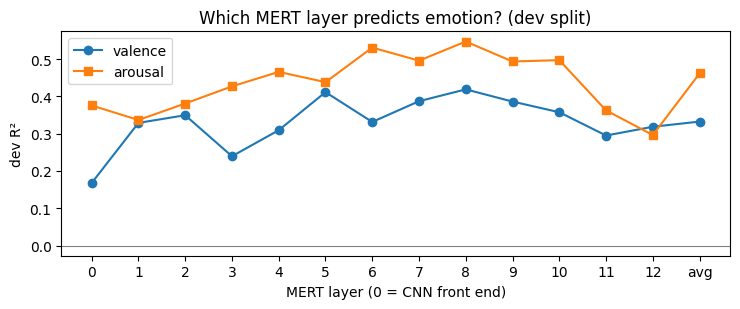

In [28]:
sweep = []
for layer in list(range(N_LAYERS)) + ['avg']:
    X_l = layer_features(layer)
    fit = train_head(X_l, Y, tr, dv)
    m = va_metrics(Y[dv], fit['predict'](X_l[dv]))
    sweep.append(dict(layer=str(layer), best_epoch=fit['best_epoch'], **m))
    print(f"layer {str(layer):>3}: dev R2 valence {m['valence_r2']:.3f} | arousal {m['arousal_r2']:.3f}")
sweep = pd.DataFrame(sweep)
sweep.to_csv(os.path.join(OUT_DIR, 'layer_sweep_dev.csv'), index=False)
BEST_LAYER = sweep.loc[sweep.mean_r2.idxmax(), 'layer']
print('best layer on dev (mean of valence and arousal R2):', BEST_LAYER)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(len(sweep))
ax.plot(xs, sweep.valence_r2, 'o-', label='valence')
ax.plot(xs, sweep.arousal_r2, 's-', label='arousal')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(xs, sweep.layer)
ax.set(xlabel='MERT layer (0 = CNN front end)', ylabel='dev R²', title='Which MERT layer predicts emotion? (dev split)')
ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'layer_sweep_dev.png'), dpi=150); plt.show()

### 3b · Small regularization check on the chosen layer (also dev only)

In [29]:
X = layer_features(BEST_LAYER)
grid = [dict(DEFAULT_HP, p_drop=p, weight_decay=wd) for p in (0.1, 0.3, 0.5) for wd in (1e-4, 1e-3, 1e-2)]
runs = []
for hp in grid:
    fit = train_head(X, Y, tr, dv, hp)
    runs.append((va_metrics(Y[dv], fit['predict'](X[dv])), fit))
    print(f"dropout {hp['p_drop']}, weight_decay {hp['weight_decay']:g}: dev mean R2 {runs[-1][0]['mean_r2']:.3f}")
best_m, best_fit = max(runs, key=lambda r: r[0]['mean_r2'])
BEST_HP = best_fit['hp']
print('chosen:', {k: BEST_HP[k] for k in ('p_drop', 'weight_decay')}, '| stopped at epoch', best_fit['best_epoch'])

dropout 0.1, weight_decay 0.0001: dev mean R2 0.480
dropout 0.1, weight_decay 0.001: dev mean R2 0.481
dropout 0.1, weight_decay 0.01: dev mean R2 0.485
dropout 0.3, weight_decay 0.0001: dev mean R2 0.483
dropout 0.3, weight_decay 0.001: dev mean R2 0.484
dropout 0.3, weight_decay 0.01: dev mean R2 0.486
dropout 0.5, weight_decay 0.0001: dev mean R2 0.465
dropout 0.5, weight_decay 0.001: dev mean R2 0.465
dropout 0.5, weight_decay 0.01: dev mean R2 0.467
chosen: {'p_drop': 0.3, 'weight_decay': 0.01} | stopped at epoch 3


### 3c · Dev summary and the controlled comparison
- **Mean predictor**: always predicts the train-set average (R² ≈ 0); anything useful must beat it.
- **openSMILE + ridge**: P1's baseline features and model, refit here on the same rows (should match P1's numbers).
- **openSMILE + MLP head** vs **MERT + MLP head**: the proposal's controlled comparison. Same head, same hyper-parameters, same split; only the input features change.
- **MERT + ridge**: a linear probe on the same MERT layer. If the MLP does not beat it, the nonlinearity is not helping.

In [30]:
def best_ridge(F):
    # Ridge on train-standardized features; alpha picked on dev, like P1 did.
    mu, sd = F[tr].mean(0), F[tr].std(0) + 1e-6
    runs = [(a, va_metrics(Y[dv], Ridge(alpha=a).fit((F[tr] - mu) / sd, Y[tr]).predict((F[dv] - mu) / sd)))
            for a in (0.1, 1, 10, 100, 1000, 10000)]
    return max(runs, key=lambda r: r[1]['mean_r2'])

rows = [dict(model='mean predictor', **va_metrics(Y[dv], np.repeat(Y[tr].mean(0, keepdims=True), len(dv), 0)))]

# openSMILE features from P1, aligned to our song order (missing values -> train median, as in P1)
X_os = None
if os.path.exists(P1_FEATURES):
    os_df = pd.read_csv(P1_FEATURES)
    feat_cols = [c for c in os_df.columns if c not in ('song_id', *TARGETS)]
    os_df = songs[['song_id']].merge(os_df[['song_id', *feat_cols]], on='song_id', how='left')
    if os_df[feat_cols].notna().any(axis=1).all():
        X_os = os_df[feat_cols].to_numpy(np.float64)
        X_os = np.where(np.isnan(X_os), np.nanmedian(X_os[tr], axis=0), X_os)
        X_os = np.nan_to_num(X_os).astype(np.float32)
    else:
        print('Some songs have no openSMILE row in P1_FEATURES; skipping the openSMILE comparison.')
else:
    print('P1_FEATURES not found; skipping the openSMILE comparison:', P1_FEATURES)
if X_os is not None:
    a_os, m_os = best_ridge(X_os)
    rows.append(dict(model=f'openSMILE ({X_os.shape[1]} feats) + ridge (alpha={a_os}) [P1 baseline]', **m_os))
    fit_os = train_head(X_os, Y, tr, dv, BEST_HP)
    rows.append(dict(model='openSMILE + MLP head (same head)', **va_metrics(Y[dv], fit_os['predict'](X_os[dv]))))

alpha, ridge_m = best_ridge(X)
rows.append(dict(model=f'MERT layer {BEST_LAYER} + ridge (alpha={alpha})', **ridge_m))
rows.append(dict(model=f'MERT layer {BEST_LAYER} + MLP head (C2)', **best_m))
dev_summary = pd.DataFrame(rows).set_index('model')
dev_summary.to_csv(os.path.join(OUT_DIR, 'dev_summary.csv'))
print(dev_summary.round(3).to_string())

                                                         valence_r2  valence_rmse  arousal_r2  arousal_rmse  mean_r2
model                                                                                                               
mean predictor                                               -0.037         1.098      -0.002         1.233   -0.020
openSMILE (260 feats) + ridge (alpha=100) [P1 baseline]       0.223         0.951       0.384         0.967    0.303
openSMILE + MLP head (same head)                              0.204         0.962       0.469         0.898    0.336
MERT layer 8 + ridge (alpha=1000)                             0.372         0.855       0.545         0.831    0.459
MERT layer 8 + MLP head (C2)                                  0.426         0.817       0.546         0.831    0.486


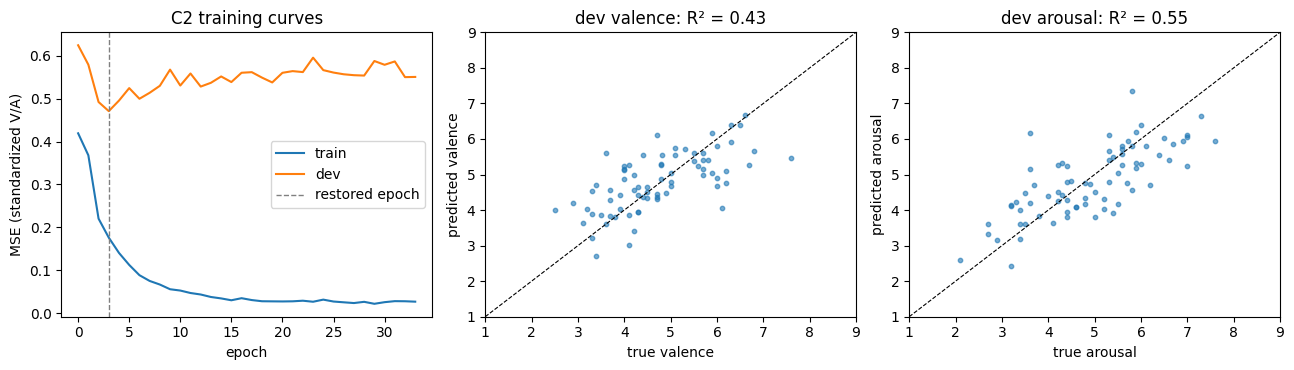

In [31]:
h = best_fit['hist']
pred_dv = best_fit['predict'](X[dv])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(h['train'], label='train'); axes[0].plot(h['dev'], label='dev')
axes[0].axvline(best_fit['best_epoch'], ls='--', c='gray', lw=1, label='restored epoch')
axes[0].set(xlabel='epoch', ylabel='MSE (standardized V/A)', title='C2 training curves'); axes[0].legend()
for j, name in enumerate(['valence', 'arousal']):
    ax = axes[j + 1]
    ax.scatter(Y[dv, j], pred_dv[:, j], s=10, alpha=0.6)
    ax.plot([1, 9], [1, 9], 'k--', lw=0.8)
    ax.set(xlim=(1, 9), ylim=(1, 9), xlabel=f'true {name}', ylabel=f'predicted {name}',
           title=f'dev {name}: R² = {r2_score(Y[dv, j], pred_dv[:, j]):.2f}')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'training_curves_and_dev_scatter.png'), dpi=150); plt.show()

## 4 · Save outputs for the team
`p2_va_for_p4.csv` is the hand-off to **P4**: it has the same `song_id, split, valence, arousal` columns P4's ranker already reads from P1's Ridge model, so it is a drop-in swap.
Predictions for train songs are optimistic (the head saw them), so tune the ranker on **dev** rows and report mood-hit@10 on **test** rows once, at the end.

In [32]:
torch.save({'state_dict': best_fit['model'].state_dict(), 'layer': str(BEST_LAYER), 'hp': BEST_HP,
            **{k: torch.as_tensor(v) for k, v in best_fit['stats'].items()}},
           os.path.join(OUT_DIR, 'va_head.pt'))
pred_all = best_fit['predict'](X)
pd.DataFrame({'song_id': songs.song_id, 'split': songs['split'],
              'valence_true': Y[:, 0], 'arousal_true': Y[:, 1],
              'valence_pred': pred_all[:, 0].round(4), 'arousal_pred': pred_all[:, 1].round(4)}
             ).to_csv(os.path.join(OUT_DIR, 'va_predictions.csv'), index=False)
pd.DataFrame({'song_id': songs.song_id, 'split': songs['split'],
              'valence': pred_all[:, 0].round(4), 'arousal': pred_all[:, 1].round(4)}
             ).to_csv(os.path.join(OUT_DIR, 'p2_va_for_p4.csv'), index=False)
with open(os.path.join(OUT_DIR, 'va_head_config.json'), 'w') as f:
    json.dump({'mert_model': MERT_ID, 'chunk_seconds': CHUNK_S, 'layer': str(BEST_LAYER), 'hp': BEST_HP,
               'split_source': SPLIT_SOURCE, 'songs_per_split': {k: int(len(v)) for k, v in SPLIT_IDX.items()},
               'dev_metrics': {k: round(float(v), 4) for k, v in best_m.items()}, 'scale': 'DEAM 1-9'}, f, indent=2)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

saved to /content/drive/MyDrive/ECE539-mood-music/outputs/p2 : ['dev_summary.csv', 'layer_sweep_dev.csv', 'layer_sweep_dev.png', 'mert_embeddings.npz', 'p2_va_for_p4.csv', 'provisional_splits.csv', 'training_curves_and_dev_scatter.png', 'va_head.pt', 'va_head_config.json', 'va_predictions.csv']


In [33]:
# Inference helper for P4's demo: any audio file -> (valence, arousal).
def predict_va_from_audio(path):
    emb = embed_audio(path).astype(np.float32)[None]               # (1, 13, 768)
    x = emb.mean(axis=1) if BEST_LAYER == 'avg' else emb[:, int(BEST_LAYER), :]
    v, a = best_fit['predict'](x)[0]
    return round(float(v), 2), round(float(a), 2)

ex = songs[songs['split'] == 'dev'].iloc[0]
print(f"song {ex.song_id}: true ({ex[TARGETS[0]]:.2f}, {ex[TARGETS[1]]:.2f})  predicted {predict_va_from_audio(ex['path'])}")

song 8: true (3.20, 4.80)  predicted (4.03, 4.35)


## 5 · Final test (run once, as a team)
Flip `RUN_FINAL_TEST` to `True` only after the layer, hyper-parameters and the ranker are frozen.

In [34]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    te = SPLIT_IDX['test']
    test_df = pd.DataFrame({
        'mean predictor': va_metrics(Y[te], np.repeat(Y[tr].mean(0, keepdims=True), len(te), 0)),
        f'MERT layer {BEST_LAYER} + MLP head (C2)': va_metrics(Y[te], best_fit['predict'](X[te])),
    }).T
    test_df.to_csv(os.path.join(OUT_DIR, 'final_test_metrics.csv'))
    print(test_df.round(3).to_string())
else:
    print('Test split untouched (RUN_FINAL_TEST = False).')

Test split untouched (RUN_FINAL_TEST = False).


## Next steps
1. **Hand-off to P4:** share `p2_va_for_p4.csv`; it replaces P1's Ridge predictions in P4's ranker without code changes.
2. **Scale up:** P1's split covers 500 songs. Once the team agrees, extend the split to all ~1,800 DEAM songs (the proposal's fallback); cached embeddings make reruns cheap.
3. **Report:** `dev_summary.csv` is the controlled comparison table; `layer_sweep_dev.png` and `training_curves_and_dev_scatter.png` are the figures. Discuss why valence is harder than arousal.
4. Upload this executed notebook to the repo's `p2/` folder.